# Walk-forward results: exploring the Poisson model

Run `python -m src.run_walkforward` first (in a terminal, or from VS Code's integrated terminal).
It writes the files in `reports/` that this notebook reads. Every cell can be re-run on its own.
Kernel: **Python (epl)**.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import metrics as M
from src import poisson as P
from src.run_walkforward import ODDS_SOURCES
from src.walkforward import fit_before, load_matches, team_strengths

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

RUN_DIR = "reports"  # after `--grid wide --out-dir reports/wide`, set this to "reports/wide"
REPORTS = ROOT / RUN_DIR
df, teams = load_matches(ROOT / "data/processed/matches.csv")
T = len(teams)
val = pd.read_csv(REPORTS / "validation_grid.csv")
pred = pd.read_csv(REPORTS / "test_predictions.csv", parse_dates=["Date"])
print(f"{len(df)} matches, {T} teams; {len(pred)} test-window predictions")

4240 matches, 35 teams; 1140 test-window predictions


## 1. Which decay rate and ridge strength won?

Walk-forward log loss on the validation window (2021/22 and 2022/23) for each setting. Darker is
better. If the darkest cell sits on the edge of the grid, the search should be widened
(`python -m src.run_walkforward --grid wide`).

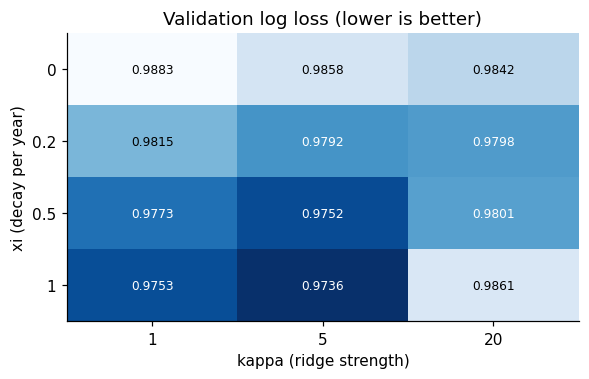

Best: xi=1 (half-life 0.69 years), kappa=5, log loss 0.9736


In [2]:
grid = val.pivot(index="xi", columns="kappa", values="log_loss")
fig, ax = plt.subplots(figsize=(6, 1.0 + 0.6 * len(grid)))
im = ax.imshow(grid.values, cmap="Blues_r", aspect="auto")
ax.set_xticks(range(len(grid.columns)), [f"{c:g}" for c in grid.columns])
ax.set_yticks(range(len(grid.index)), [f"{x:g}" for x in grid.index])
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j]
        ax.text(j, i, f"{v:.4f}", ha="center", va="center", fontsize=8,
                color="white" if v < grid.values.mean() else "black")
ax.set_xlabel("kappa (ridge strength)")
ax.set_ylabel("xi (decay per year)")
ax.set_title("Validation log loss (lower is better)")
plt.show()

best = val.sort_values("log_loss").iloc[0]
xi, kappa = float(best["xi"]), float(best["kappa"])
half_life = np.log(2) / xi if xi > 0 else float("inf")
print(f"Best: xi={xi:g} (half-life {half_life:.2f} years), kappa={kappa:g}, log loss {best['log_loss']:.4f}")

## 2. Where does the model lose to the bookmakers?

For each test match, the model's log loss minus the Average-odds log loss, added up over time.
A rising line means the model is falling behind; a flat line means it is keeping pace.

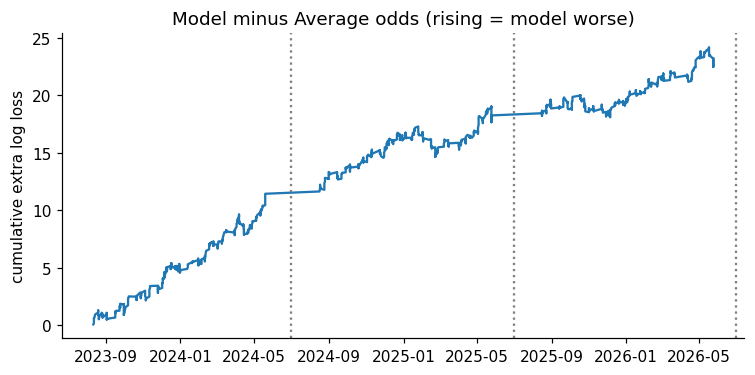

Average gap: 0.0202 log loss per match over 1140 matches


In [3]:
odds_cols = ODDS_SOURCES["Avg"]
assert all(c in df.columns for c in odds_cols), "Average-odds columns not found in matches.csv"
test = pred.merge(df[["Date", "HomeTeam", "AwayTeam"] + odds_cols], on=["Date", "HomeTeam", "AwayTeam"], how="left")
y = test["FTR"].map({"H": 0, "D": 1, "A": 2}).values
model_p = test[["pH", "pD", "pA"]].values
has_odds = test[odds_cols].notna().all(axis=1).values
book_p = np.full_like(model_p, np.nan)
book_p[has_odds] = M.implied_probs(test.loc[has_odds, odds_cols].values.astype(float))


def per_match_loss(p, y):
    return -np.log(np.clip(p[np.arange(len(y)), y], 1e-15, 1.0))


loss_model = per_match_loss(model_p, y)
loss_book = per_match_loss(np.nan_to_num(book_p, nan=1 / 3), y)
diff = np.where(has_odds, loss_model - loss_book, 0.0)  # positive = model worse

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(test["Date"], np.cumsum(diff))
for yr in (2024, 2025, 2026):
    ax.axvline(pd.Timestamp(f"{yr}-07-01"), ls=":", color="grey")
ax.set_ylabel("cumulative extra log loss")
ax.set_title("Model minus Average odds (rising = model worse)")
plt.show()
print(f"Average gap: {diff[has_odds].mean():.4f} log loss per match over {has_odds.sum()} matches")

## 3. Calibration: do predicted probabilities match reality?

Matches are sorted by predicted probability and split into 8 equal-sized groups. If a model says
30% for a group of matches, about 30% of them should happen. Points on the grey diagonal are
perfectly calibrated.

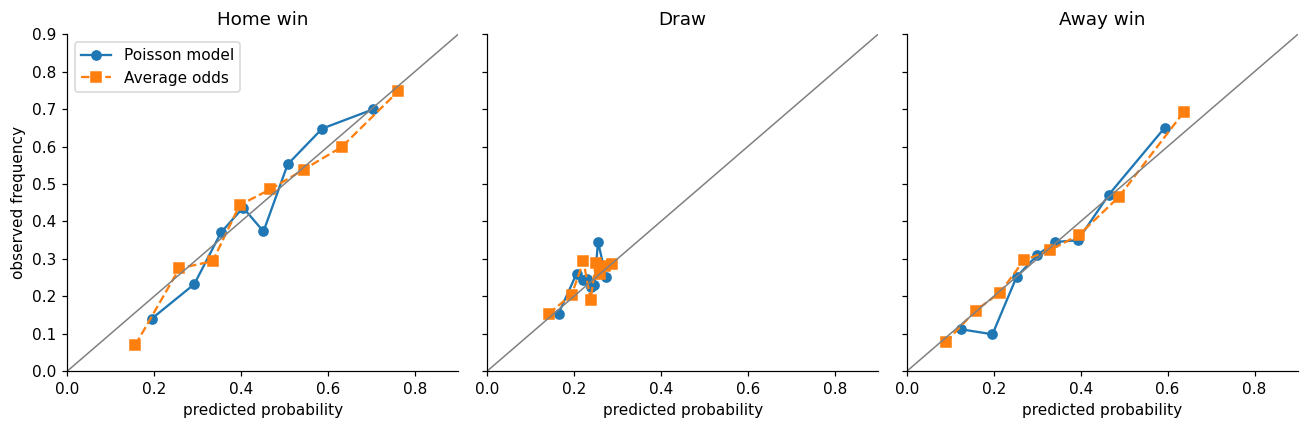

In [4]:
def calibration_points(p, hit, n_bins=8):
    bins = pd.qcut(p, n_bins, duplicates="drop")
    return pd.DataFrame({"p": p, "hit": hit}).groupby(bins, observed=True).agg(
        p=("p", "mean"), hit=("hit", "mean"), n=("p", "size")
    )


fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)
for k, (ax, name) in enumerate(zip(axes, ["Home win", "Draw", "Away win"])):
    hit = (y == k).astype(float)
    g = calibration_points(model_p[:, k], hit)
    ax.plot(g["p"], g["hit"], "o-", label="Poisson model")
    if has_odds.any():
        gb = calibration_points(book_p[has_odds, k], hit[has_odds])
        ax.plot(gb["p"], gb["hit"], "s--", label="Average odds")
    ax.plot([0, 0.9], [0, 0.9], color="grey", lw=1)
    ax.set_xlim(0, 0.9)
    ax.set_ylim(0, 0.9)
    ax.set_title(name)
    ax.set_xlabel("predicted probability")
axes[0].set_ylabel("observed frequency")
axes[0].legend()
plt.tight_layout()
plt.show()

## 4. How often does the model predict draws?

Draws are the hardest outcome for any model: they are rarely the single most likely result, so
accuracy understates quality and log loss matters more.

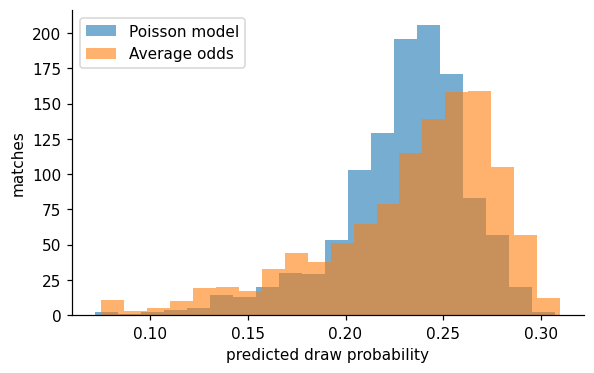

Actual draw rate 0.245; model mean 0.230; bookmaker mean 0.233


In [5]:
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.hist(model_p[:, 1], bins=20, alpha=0.6, label="Poisson model")
if has_odds.any():
    ax.hist(book_p[has_odds, 1], bins=20, alpha=0.6, label="Average odds")
ax.set_xlabel("predicted draw probability")
ax.set_ylabel("matches")
ax.legend()
plt.show()
print(f"Actual draw rate {np.mean(y == 1):.3f}; model mean {model_p[:, 1].mean():.3f}"
      + (f"; bookmaker mean {book_p[has_odds, 1].mean():.3f}" if has_odds.any() else ""))

## 5. Team strengths from the final fit

Fitted on every match to date with the winning settings. **Attack** is how much a team's scoring
rate sits above average on the log scale; **defence** is how much its conceding rate sits below.
The `recent_matches` column counts a team's matches in the last 400 days: teams with only a few
(newly promoted ones) are pulled towards the league average by the ridge penalty, so their
estimates are the least reliable.

league level iota=0.243, home advantage eta=0.182 -> average away goals 1.27, home goals 1.53


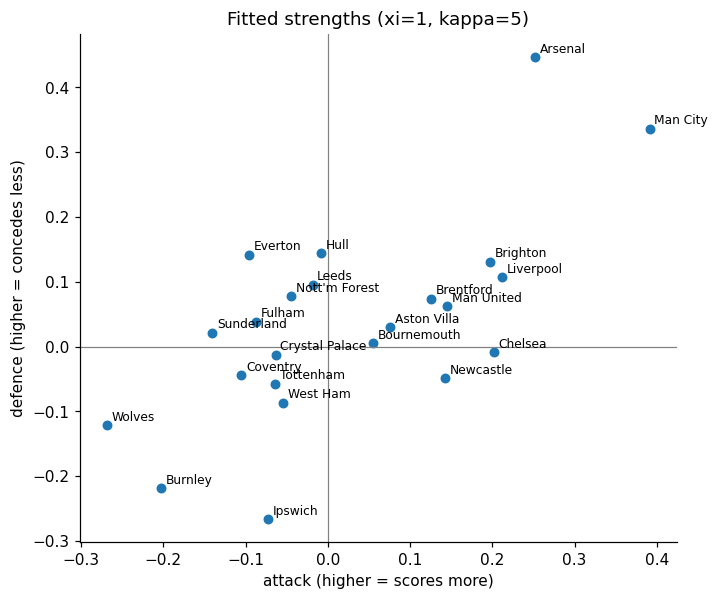

,team,attack,defence,recent_matches
0,Man City,0.391,0.337,41
1,Arsenal,0.252,0.447,41
2,Liverpool,0.211,0.107,41
3,Chelsea,0.202,-0.009,41
4,Brighton,0.197,0.131,41
5,Man United,0.145,0.063,41
6,Newcastle,0.142,-0.049,41
7,Brentford,0.125,0.074,41
8,Aston Villa,0.076,0.030,41
9,Bournemouth,0.055,0.005,41


In [6]:
last = df["Date"].max() + pd.Timedelta(days=1)
final = fit_before(df, last, T, xi, kappa)
iota, eta, _, _ = final.unpack(T)
print(f"league level iota={iota:.3f}, home advantage eta={eta:.3f} "
      f"-> average away goals {np.exp(iota):.2f}, home goals {np.exp(iota + eta):.2f}")

recent = df[df["Date"] >= last - pd.Timedelta(days=400)]
n_recent = pd.concat([recent["HomeTeam"], recent["AwayTeam"]]).value_counts()
s = team_strengths(final.theta, teams, T)
s = s[s["team"].isin(n_recent.index)].assign(recent_matches=lambda d: d["team"].map(n_recent))

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(s["attack"], s["defence"], s=30)
for _, r in s.iterrows():
    ax.annotate(r["team"], (r["attack"], r["defence"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.axhline(0, color="grey", lw=0.8)
ax.axvline(0, color="grey", lw=0.8)
ax.set_xlabel("attack (higher = scores more)")
ax.set_ylabel("defence (higher = concedes less)")
ax.set_title(f"Fitted strengths (xi={xi:g}, kappa={kappa:g})")
plt.show()

s.sort_values("attack", ascending=False).round(3).reset_index(drop=True)

## 6. Try a fixture

Predicted goal rates and outcome probabilities for any pairing, using the final fit.
Change the team names to any name in `teams`.

In [7]:
def predict_fixture(home, away, max_goals=10):
    h, a = teams.index(home), teams.index(away)
    lam, mu = P.rates(final.theta, np.array([h]), np.array([a]), T)
    p_home, p_draw, p_away = P.outcome_probs(lam, mu, max_goals)[0]
    print(f"{home} v {away}: expected goals {lam[0]:.2f} - {mu[0]:.2f}  ->  "
          f"home {p_home:.1%}, draw {p_draw:.1%}, away {p_away:.1%}")


ranked = s.sort_values("attack", ascending=False)["team"].tolist()
predict_fixture(ranked[0], ranked[-1])
predict_fixture(ranked[-1], ranked[0])

Man City v Wolves: expected goals 2.55 - 0.70  ->  home 77.5%, draw 14.5%, away 8.0%
Wolves v Man City: expected goals 0.84 - 2.13  ->  home 13.6%, draw 19.3%, away 67.1%
